In [1]:
import glob
import logging
import os
import sys
import time
import numpy as np
import pandas as pd
import torch
from tqdm import tqdm
from transformers import AutoModelForSequenceClassification, AutoTokenizer

# --- Parámetros ajustados para GTX 1650 Super (4 GB VRAM) + i7-930 ---
MODELO_ID = "tabularisai/multilingual-sentiment-analysis"
ARCHIVO_ENTRADA = "corpus_listo_inferencia.parquet"
CARPETA_CHECKPOINTS = "checkpoints_fase2"
ARCHIVO_FRAGMENTOS = "sentimiento_por_fragmento.parquet"
ARCHIVO_NOTICIAS = "sentimiento_por_noticia.parquet"

BATCH_SIZE = 32          # Seguro para 4 GB VRAM en FP16 con max_length=512
FILAS_POR_BLOQUE = 5000  # Guarda checkpoint en disco cada 5,000 fragmentos
MAX_LENGTH = 512


class TqdmLoggingHandler(logging.Handler):
    def emit(self, record: logging.LogRecord) -> None:
        try:
            tqdm.write(self.format(record))
            self.flush()
        except Exception:
            self.handleError(record)


def configurar_logger(archivo_log: str = "inferencia_fase2.log") -> logging.Logger:
    logger = logging.getLogger("InferenciaSentimiento")
    logger.setLevel(logging.INFO)
    logger.handlers.clear()

    formato = logging.Formatter(
        fmt="%(asctime)s | %(levelname)-7s | %(message)s",
        datefmt="%Y-%m-%d %H:%M:%S",
    )

    ch = TqdmLoggingHandler()
    ch.setFormatter(formato)
    logger.addHandler(ch)

    fh = logging.FileHandler(archivo_log, mode="a", encoding="utf-8")
    fh.setFormatter(formato)
    logger.addHandler(fh)
    return logger


def main() -> None:
    inicio_total = time.perf_counter()
    logger = configurar_logger()

    if not os.path.exists(ARCHIVO_ENTRADA):
        logger.error(f"No se encontró '{ARCHIVO_ENTRADA}'. Ejecuta primero preparar_corpus.py.")
        sys.exit(1)

    # 1. Verificar dispositivo
    if torch.cuda.is_available():
        device = torch.device("cuda")
        dtype = torch.float16
        nombre_gpu = torch.cuda.get_device_name(0)
        vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
        logger.info(f"GPU detectada: {nombre_gpu} ({vram_gb:.1f} GB VRAM) | Precisión: FP16")
    else:
        device = torch.device("cpu")
        dtype = torch.float32
        logger.warning("CUDA no disponible. Ejecutando en CPU (será considerablemente más lento).")

    # 2. Cargar corpus y ordenar por longitud para minimizar padding en GPU
    logger.info(f"Cargando '{ARCHIVO_ENTRADA}'...")
    df = pd.read_parquet(ARCHIVO_ENTRADA).reset_index(drop=True)
    df["_orden_original"] = df.index
    df["_len_chars"] = df["texto_modelo"].str.len()
    df = df.sort_values("_len_chars", ascending=True).reset_index(drop=True)
    total_fragmentos = len(df)
    logger.info(f"Total de fragmentos a evaluar: {total_fragmentos:,} ({df['id'].nunique():,} noticias).")

    # 3. Cargar modelo y tokenizador
    logger.info(f"Cargando modelo '{MODELO_ID}'...")
    tokenizer = AutoTokenizer.from_pretrained(MODELO_ID)
    model = AutoModelForSequenceClassification.from_pretrained(MODELO_ID, torch_dtype=dtype)
    model.to(device)
    model.eval()

    # Mapear índices de salida del modelo a pesos [-2, -1, 0, +1, +2]
    id2label = model.config.id2label
    mapa_pesos = {
        "Very Negative": -2.0,
        "Negative": -1.0,
        "Neutral": 0.0,
        "Positive": 1.0,
        "Very Positive": 2.0,
    }
    pesos_vector = torch.tensor(
        [mapa_pesos[id2label[i]] for i in range(len(id2label))],
        device=device,
        dtype=torch.float32,
    )

    # 4. Procesamiento por bloques con checkpoints y barra de progreso
    os.makedirs(CARPETA_CHECKPOINTS, exist_ok=True)
    n_bloques = (total_fragmentos + FILAS_POR_BLOQUE - 1) // FILAS_POR_BLOQUE
    logger.info(f"Procesando en {n_bloques} bloques de {FILAS_POR_BLOQUE:,} fragmentos (batch_size={BATCH_SIZE})...")

    barra_general = tqdm(
        total=total_fragmentos,
        desc="Inferencia GPU",
        unit="frag",
        smoothing=0.05,
    )

    for b in range(n_bloques):
        inicio_idx = b * FILAS_POR_BLOQUE
        fin_idx = min((b + 1) * FILAS_POR_BLOQUE, total_fragmentos)
        ruta_ckpt = os.path.join(CARPETA_CHECKPOINTS, f"bloque_{b:04d}.parquet")

        # Si el checkpoint ya existe de una ejecución previa, saltarlo
        if os.path.exists(ruta_ckpt):
            barra_general.update(fin_idx - inicio_idx)
            continue

        sub_df = df.iloc[inicio_idx:fin_idx].copy()
        textos = sub_df["texto_modelo"].tolist()

        etiquetas_pred = []
        scores_max = []
        polaridades_esp = []
        probs_todas = []

        with torch.inference_mode():
            for i in range(0, len(textos), BATCH_SIZE):
                lote_textos = textos[i : i + BATCH_SIZE]
                inputs = tokenizer(
                    lote_textos,
                    padding=True,
                    truncation=True,
                    max_length=MAX_LENGTH,
                    return_tensors="pt",
                ).to(device)

                logits = model(**inputs).logits.float()
                probs = torch.softmax(logits, dim=-1)

                max_p, max_idx = torch.max(probs, dim=-1)
                polaridad_continua = torch.matmul(probs, pesos_vector)

                etiquetas_pred.extend([id2label[idx.item()] for idx in max_idx])
                scores_max.extend(max_p.cpu().numpy().tolist())
                polaridades_esp.extend(polaridad_continua.cpu().numpy().tolist())
                probs_todas.append(probs.cpu().numpy())

                barra_general.update(len(lote_textos))

        matriz_probs = np.vstack(probs_todas)
        sub_df["etiqueta_chunk"] = etiquetas_pred
        sub_df["score_chunk"] = np.round(scores_max, 4)
        sub_df["polaridad_chunk"] = np.round(polaridades_esp, 4)

        for idx_clase, nombre_clase in id2label.items():
            col_prob = "prob_" + nombre_clase.lower().replace(" ", "_")
            sub_df[col_prob] = np.round(matriz_probs[:, idx_clase], 4)

        # Eliminar el texto crudo en los checkpoints para ahorrar espacio en disco
        sub_df = sub_df.drop(columns=["texto_modelo", "_len_chars"])
        sub_df.to_parquet(ruta_ckpt, index=False)

    barra_general.close()

    # 5. Unir todos los checkpoints y restaurar orden original
    logger.info("Consolidando checkpoints y generando archivos finales...")
    archivos_ckpt = sorted(glob.glob(os.path.join(CARPETA_CHECKPOINTS, "bloque_*.parquet")))
    df_resultados = (
        pd.concat([pd.read_parquet(f) for f in archivos_ckpt], ignore_index=True)
        .sort_values("_orden_original")
        .drop(columns=["_orden_original"])
        .reset_index(drop=True)
    )
    df_resultados.to_parquet(ARCHIVO_FRAGMENTOS, index=False)

    # 6. Agregar a nivel de noticia única (id) conservando metadatos clave
    cols_grupo = [
        c for c in ["id", "idioma", "diario", "tipo", "rol", "fecha_final", "anio_pub", "mes_pub", "origen_url"]
        if c in df_resultados.columns
    ]

    df_noticias = (
        df_resultados.groupby(cols_grupo, as_index=False, dropna=False)
        .agg(
            polaridad_media=("polaridad_chunk", "mean"),
            polaridad_min=("polaridad_chunk", "min"),
            polaridad_max=("polaridad_chunk", "max"),
            prob_very_negative=("prob_very_negative", "mean"),
            prob_negative=("prob_negative", "mean"),
            prob_neutral=("prob_neutral", "mean"),
            prob_positive=("prob_positive", "mean"),
            prob_very_positive=("prob_very_positive", "mean"),
            etiqueta_predominante=("etiqueta_chunk", lambda x: x.mode().iloc[0]),
            n_chunks=("chunk_id", "count"),
        )
    )

    for col in ["polaridad_media", "polaridad_min", "polaridad_max",
                "prob_very_negative", "prob_negative", "prob_neutral",
                "prob_positive", "prob_very_positive"]:
        df_noticias[col] = df_noticias[col].round(4)

    df_noticias.to_parquet(ARCHIVO_NOTICIAS, index=False)

    duracion = time.perf_counter() - inicio_total
    logger.info("=" * 65)
    logger.info("FASE 2 COMPLETADA EXITOSAMENTE")
    logger.info(f"  • Tiempo total:             {duracion / 60:.2f} minutos ({total_fragmentos / duracion:.1f} frag/seg)")
    logger.info(f"  • Fragmentos clasificados:  {len(df_resultados):,}")
    logger.info(f"  • Noticias consolidadas:    {len(df_noticias):,}")
    logger.info(f"  • Salida por fragmento:     '{ARCHIVO_FRAGMENTOS}'")
    logger.info(f"  • Salida por noticia (id):  '{ARCHIVO_NOTICIAS}'")
    logger.info("=" * 65)


if __name__ == "__main__":
    main()

INFO:InferenciaSentimiento:GPU detectada: Tesla T4 (14.6 GB VRAM) | Precisión: FP16
INFO:InferenciaSentimiento:Cargando 'corpus_listo_inferencia.parquet'...


2026-11-17 00:03:56 | INFO    | GPU detectada: Tesla T4 (14.6 GB VRAM) | Precisión: FP16
2026-11-17 00:03:56 | INFO    | Cargando 'corpus_listo_inferencia.parquet'...


INFO:InferenciaSentimiento:Total de fragmentos a evaluar: 140,260 (78,371 noticias).
INFO:InferenciaSentimiento:Cargando modelo 'tabularisai/multilingual-sentiment-analysis'...


2026-11-17 00:03:58 | INFO    | Total de fragmentos a evaluar: 140,260 (78,371 noticias).
2026-11-17 00:03:58 | INFO    | Cargando modelo 'tabularisai/multilingual-sentiment-analysis'...


config.json:   0%|          | 0.00/851 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

... (9 outputs left out)

Inferencia GPU: 100%|██████████| 140260/140260 [08:01<00:00, 291.50frag/s]
INFO:InferenciaSentimiento:Consolidando checkpoints y generando archivos finales...


2026-11-17 00:12:16 | INFO    | Consolidando checkpoints y generando archivos finales...


INFO:InferenciaSentimiento:=================================================================
INFO:InferenciaSentimiento:FASE 2 COMPLETADA EXITOSAMENTE
INFO:InferenciaSentimiento:  • Tiempo total:             8.47 minutos (276.0 frag/seg)
INFO:InferenciaSentimiento:  • Fragmentos clasificados:  140,260
INFO:InferenciaSentimiento:  • Noticias consolidadas:    78,371
INFO:InferenciaSentimiento:  • Salida por fragmento:     'sentimiento_por_fragmento.parquet'
INFO:InferenciaSentimiento:  • Salida por noticia (id):  'sentimiento_por_noticia.parquet'
INFO:InferenciaSentimiento:=================================================================


2026-11-17 00:12:24 | INFO    | =================================================================
2026-11-17 00:12:24 | INFO    | FASE 2 COMPLETADA EXITOSAMENTE
2026-11-17 00:12:24 | INFO    |   • Tiempo total:             8.47 minutos (276.0 frag/seg)
2026-11-17 00:12:24 | INFO    |   • Fragmentos clasificados:  140,260
2026-11-17 00:12:24 | INFO    |   • Noticias consolidadas:    78,371
2026-11-17 00:12:24 | INFO    |   • Salida por fragmento:     'sentimiento_por_fragmento.parquet'
2026-11-17 00:12:24 | INFO    |   • Salida por noticia (id):  'sentimiento_por_noticia.parquet'
2026-11-17 00:12:24 | INFO    | =================================================================


In [2]:
import glob
import pandas as pd

df = pd.read_parquet("sentimiento_por_noticia.parquet")

print("=" * 70)
print(f"TOTAL NOTICIAS PROCESADAS: {len(df):,} (esperadas en corpus: ~78,371)")
print("=" * 70)

print("\n1. DISTRIBUCIÓN DE ETIQUETAS PREDOMINANTES (%):")
dist_etiquetas = (df["etiqueta_predominante"].value_counts(normalize=True) * 100).round(2)
print(dist_etiquetas.to_string())

print("\n2. POLARIDAD MEDIA Y DISTRIBUCIÓN POR IDIOMA:")
resumen_idioma = (
    df.groupby("idioma")
    .agg(
        noticias=("id", "count"),
        polaridad_media=("polaridad_media", "mean"),
        desv_std=("polaridad_media", "std"),
        pct_negativo=("polaridad_media", lambda s: (s < -0.25).mean() * 100),
        pct_neutral=("polaridad_media", lambda s: ((s >= -0.25) & (s <= 0.25)).mean() * 100),
        pct_positivo=("polaridad_media", lambda s: (s > 0.25).mean() * 100),
    )
    .round(3)
)
print(resumen_idioma.to_string())

print("\n3. COMPARACIÓN GENERALISTA VS. TECNOLOGÍA:")
resumen_tipo = (
    df.groupby(["idioma", "tipo"])["polaridad_media"]
    .agg(noticias="count", polaridad_media="mean")
    .round(3)
)
print(resumen_tipo.to_string())

# Cruzar una muestra con el texto original para auditar a ojo
archivos_orig = sorted(glob.glob("noticias_*.parquet"))
if archivos_orig:
    df_textos = pd.concat(
        [pd.read_parquet(f, columns=["id", "texto"]) for f in archivos_orig],
        ignore_index=True,
    )
    muestra = df.merge(df_textos, on="id", how="inner")

    print("\n4. EJEMPLOS EXTREMOS Y NEUTRALES (AUDITORÍA CUALITATIVA):")
    casos = pd.concat([
        muestra.nsmallest(2, "polaridad_media").assign(grupo="MÁS NEGATIVAS"),
        muestra.iloc[(muestra["polaridad_media"].abs()).argsort()[:2]].assign(grupo="MÁS NEUTRALES"),
        muestra.nlargest(2, "polaridad_media").assign(grupo="MÁS POSITIVAS"),
    ])

    for row in casos.itertuples():
        extracto = " ".join(str(row.texto).split())[:260]
        print(f"\n[{row.grupo}] {row.idioma.upper()} | {row.diario} | Polaridad: {row.polaridad_media:+.3f} ({row.etiqueta_predominante})")
        print(f"  Texto: {extracto}...")

TOTAL NOTICIAS PROCESADAS: 78,371 (esperadas en corpus: ~78,371)

1. DISTRIBUCIÓN DE ETIQUETAS PREDOMINANTES (%):
etiqueta_predominante
Neutral          87.16
Negative         11.40
Positive          0.89
Very Negative     0.42
Very Positive     0.13

2. POLARIDAD MEDIA Y DISTRIBUCIÓN POR IDIOMA:
        noticias  polaridad_media  desv_std  pct_negativo  pct_neutral  pct_positivo
idioma                                                                              
de          9593           -0.061     0.190         9.153       90.003         0.844
en         20136           -0.089     0.299        21.558       72.383         6.059
es         13053           -0.072     0.231        13.928       83.483         2.589
fr         12069           -0.118     0.278        18.444       79.717         1.839
pt         23520           -0.043     0.171         8.142       90.395         1.463

3. COMPARACIÓN GENERALISTA VS. TECNOLOGÍA:
                    noticias  polaridad_media
idioma tipo      

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Configuración visual
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 150

df = pd.read_parquet("sentimiento_por_noticia.parquet")

# 1. Crear periodo temporal híbrido (advertencia 1 y 7 de LEEME_dataset.md):
#    - 2021 y 2022 agrupados por semestre (H1/H2) por bajo volumen de noticias
#    - 2023 a 2026 por trimestre (Q1..Q4) donde el volumen supera miles por idioma
def asignar_periodo(row) -> str:
    anio = int(row["anio_pub"])
    mes = int(row["mes_pub"])
    if anio <= 2022:
        semestre = "H1" if mes <= 6 else "H2"
        return f"{anio}-{semestre}"
    trimestre = (mes - 1) // 3 + 1
    return f"{anio}-Q{trimestre}"

df["periodo"] = df.apply(asignar_periodo, axis=1)
df["es_negativa"] = (df["polaridad_media"] < -0.25).astype(int)
df["es_positiva"] = (df["polaridad_media"] > 0.25).astype(int)

# 2. Paso A: Agregar primero por (idioma, periodo, tipo, diario)
#    Esto evita que un diario con 60%-80% de cuota domine su idioma-periodo
por_diario = (
    df.groupby(["idioma", "periodo", "tipo", "diario"], as_index=False)
    .agg(
        n_noticias=("id", "count"),
        polaridad_diario=("polaridad_media", "mean"),
        pct_neg_diario=("es_negativa", lambda s: s.mean() * 100),
        pct_pos_diario=("es_positiva", lambda s: s.mean() * 100),
    )
)

# 3. Paso B: Serie temporal por idioma (peso equitativo por diario dentro de cada periodo)
serie_idioma = (
    por_diario.groupby(["idioma", "periodo"], as_index=False)
    .agg(
        n_noticias=("n_noticias", "sum"),
        n_diarios_activos=("diario", "nunique"),
        polaridad_ponderada_diario=("polaridad_diario", "mean"),
        pct_negativo=("pct_neg_diario", "mean"),
        pct_positivo=("pct_pos_diario", "mean"),
    )
    .sort_values(["idioma", "periodo"])
)

# Calcular Z-score dentro de cada idioma para comparar dinámicas relativas entre lenguas
serie_idioma["polaridad_zscore"] = (
    serie_idioma.groupby("idioma")["polaridad_ponderada_diario"]
    .transform(lambda s: (s - s.mean()) / s.std())
    .round(3)
)

# 4. Paso C: Serie temporal separando prensa Generalista vs. Tecnología
serie_tipo = (
    por_diario.groupby(["idioma", "tipo", "periodo"], as_index=False)
    .agg(
        n_noticias=("n_noticias", "sum"),
        polaridad_media=("polaridad_diario", "mean"),
        pct_negativo=("pct_neg_diario", "mean"),
    )
    .sort_values(["idioma", "tipo", "periodo"])
)

# 5. Ranking general por diario (2021-2026)
ranking_diarios = (
    df.groupby(["idioma", "diario", "tipo"], as_index=False)
    .agg(
        total_noticias=("id", "count"),
        polaridad_media=("polaridad_media", "mean"),
        pct_negativo=("es_negativa", lambda s: s.mean() * 100),
        pct_positivo=("es_positiva", lambda s: s.mean() * 100),
    )
    .sort_values(["idioma", "polaridad_media"])
    .round(3)
)

# Exportar tablas listas para análisis e informes
serie_idioma.round(4).to_csv("resultado_serie_temporal_idiomas.csv", index=False)
serie_tipo.round(4).to_csv("resultado_serie_generalista_vs_tech.csv", index=False)
ranking_diarios.to_csv("resultado_ranking_diarios.csv", index=False)

# --- GRÁFICA 1: Evolución del tono sobre IA por idioma (2021-2026) ---
periodos_ordenados = sorted(serie_idioma["periodo"].unique())
nombres_idioma = {
    "de": "Alemán (DE)",
    "en": "Inglés (EN)",
    "es": "Español (ES)",
    "fr": "Francés (FR)",
    "pt": "Portugués (PT)",
}

fig, ax = plt.subplots(figsize=(12, 5.5))
for lang, grupo in serie_idioma.groupby("idioma"):
    grupo_idx = grupo.set_index("periodo").reindex(periodos_ordenados)
    ax.plot(
        periodos_ordenados,
        grupo_idx["polaridad_ponderada_diario"],
        marker="o",
        linewidth=2,
        label=nombres_idioma.get(lang, lang),
    )

ax.axhline(0, color="black", linestyle="--", linewidth=0.9, alpha=0.6)
ax.axvline(periodos_ordenados.index("2023-Q1"), color="gray", linestyle=":", linewidth=1.2)
ax.text(
    periodos_ordenados.index("2023-Q1") + 0.15,
    ax.get_ylim()[1] * 0.9,
    "Boom ChatGPT (2023-Q1)",
    fontsize=9,
    color="dimgray",
)
ax.set_title("Evolución del tono mediático sobre IA por idioma (2021–2026)\n(Promedio equitativo por diario dentro de cada idioma)", fontsize=12, fontweight="bold")
ax.set_ylabel("Polaridad media (-2 = Muy Negativo, +2 = Muy Positivo)")
ax.set_xlabel("Periodo (Semestral 2021–2022 | Trimestral 2023–2026)")
plt.xticks(rotation=45, ha="right")
ax.legend(title="Idioma", frameon=True)
plt.tight_layout()
plt.savefig("grafica_1_evolucion_idiomas.png")
plt.close()

# --- GRÁFICA 2: Prensa Generalista vs. Tecnología (agregado multilingüe por periodo) ---
global_tipo = (
    por_diario.groupby(["tipo", "periodo"], as_index=False)
    .agg(
        polaridad_media=("polaridad_diario", "mean"),
        pct_negativo=("pct_neg_diario", "mean"),
    )
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for tipo, etiqueta, color in [
    ("generalista", "Prensa Generalista", "#d95f02"),
    ("tecnologia", "Prensa de Tecnología", "#1b9e77"),
]:
    sub = global_tipo[global_tipo["tipo"] == tipo].set_index("periodo").reindex(periodos_ordenados)
    ax1.plot(periodos_ordenados, sub["polaridad_media"], marker="o", label=etiqueta, color=color, linewidth=2)
    ax2.plot(periodos_ordenados, sub["pct_negativo"], marker="s", label=etiqueta, color=color, linewidth=2)

ax1.axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.5)
ax1.set_title("Polaridad media: Generalista vs. Tecnología", fontweight="bold")
ax1.set_ylabel("Polaridad media (-2 a +2)")
ax1.tick_params(axis="x", rotation=45)
ax1.legend()

ax2.set_title("% de cobertura negativa (polaridad < -0.25)", fontweight="bold")
ax2.set_ylabel("% Noticias negativas")
ax2.tick_params(axis="x", rotation=45)
ax2.legend()

plt.tight_layout()
plt.savefig("grafica_2_generalista_vs_tecnologia.png")
plt.close()

print("Archivos CSV y gráficas generados correctamente:")
print("  1. resultado_serie_temporal_idiomas.csv")
print("  2. resultado_serie_generalista_vs_tech.csv")
print("  3. resultado_ranking_diarios.csv")
print("  4. grafica_1_evolucion_idiomas.png")
print("  5. grafica_2_generalista_vs_tecnologia.png")

Archivos CSV y gráficas generados correctamente:
  1. resultado_serie_temporal_idiomas.csv
  2. resultado_serie_generalista_vs_tech.csv
  3. resultado_ranking_diarios.csv
  4. grafica_1_evolucion_idiomas.png
  5. grafica_2_generalista_vs_tecnologia.png


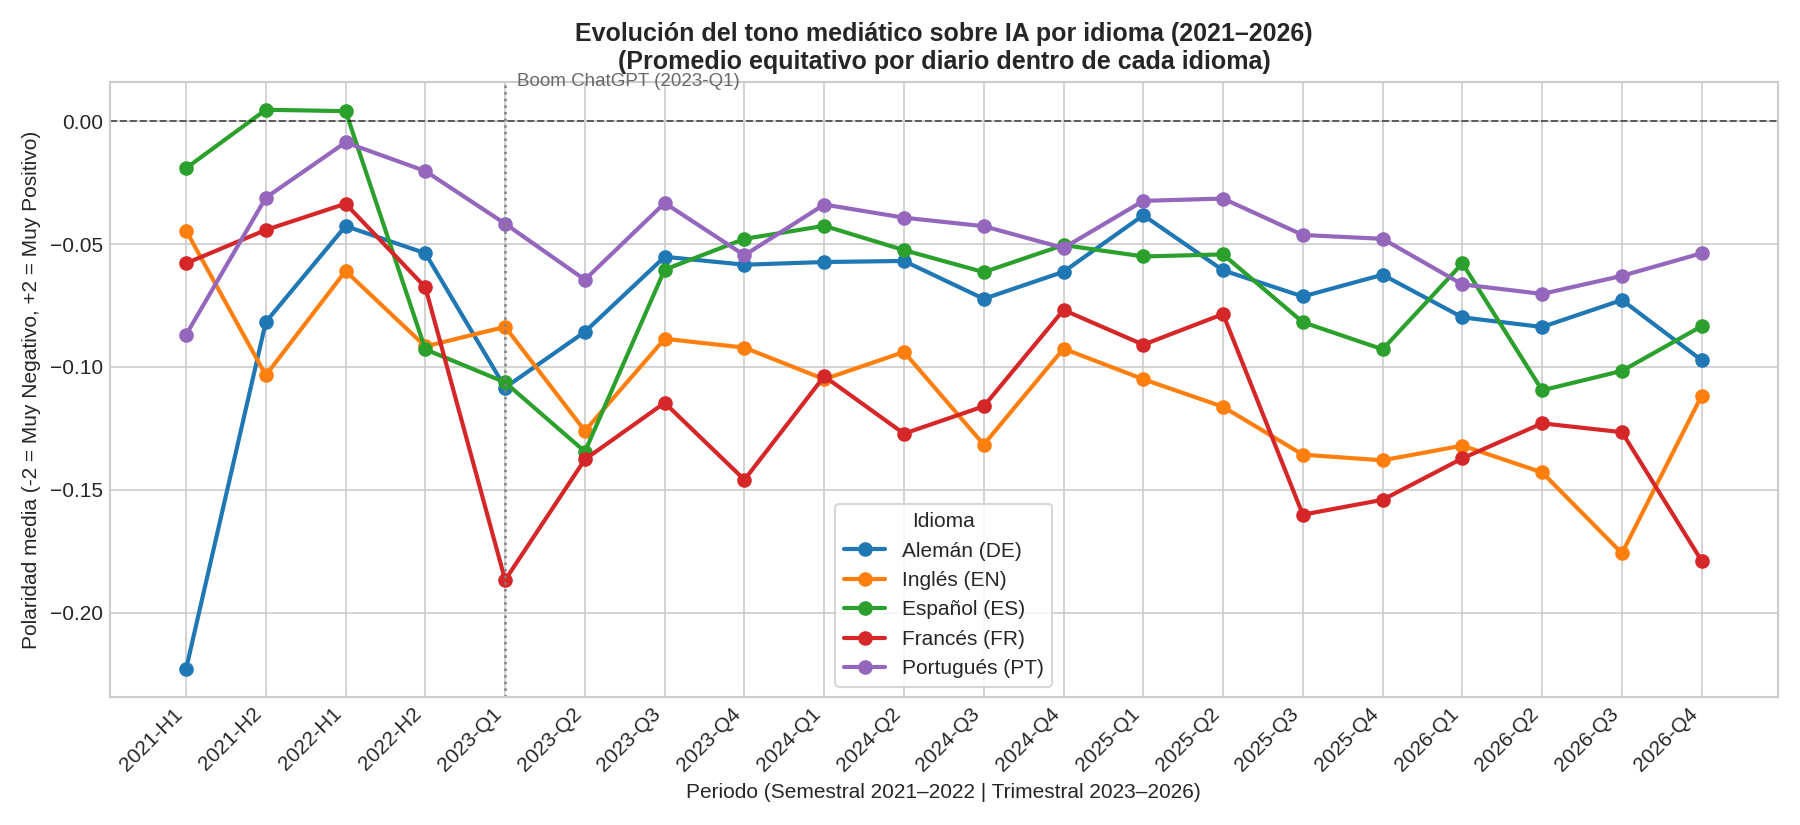

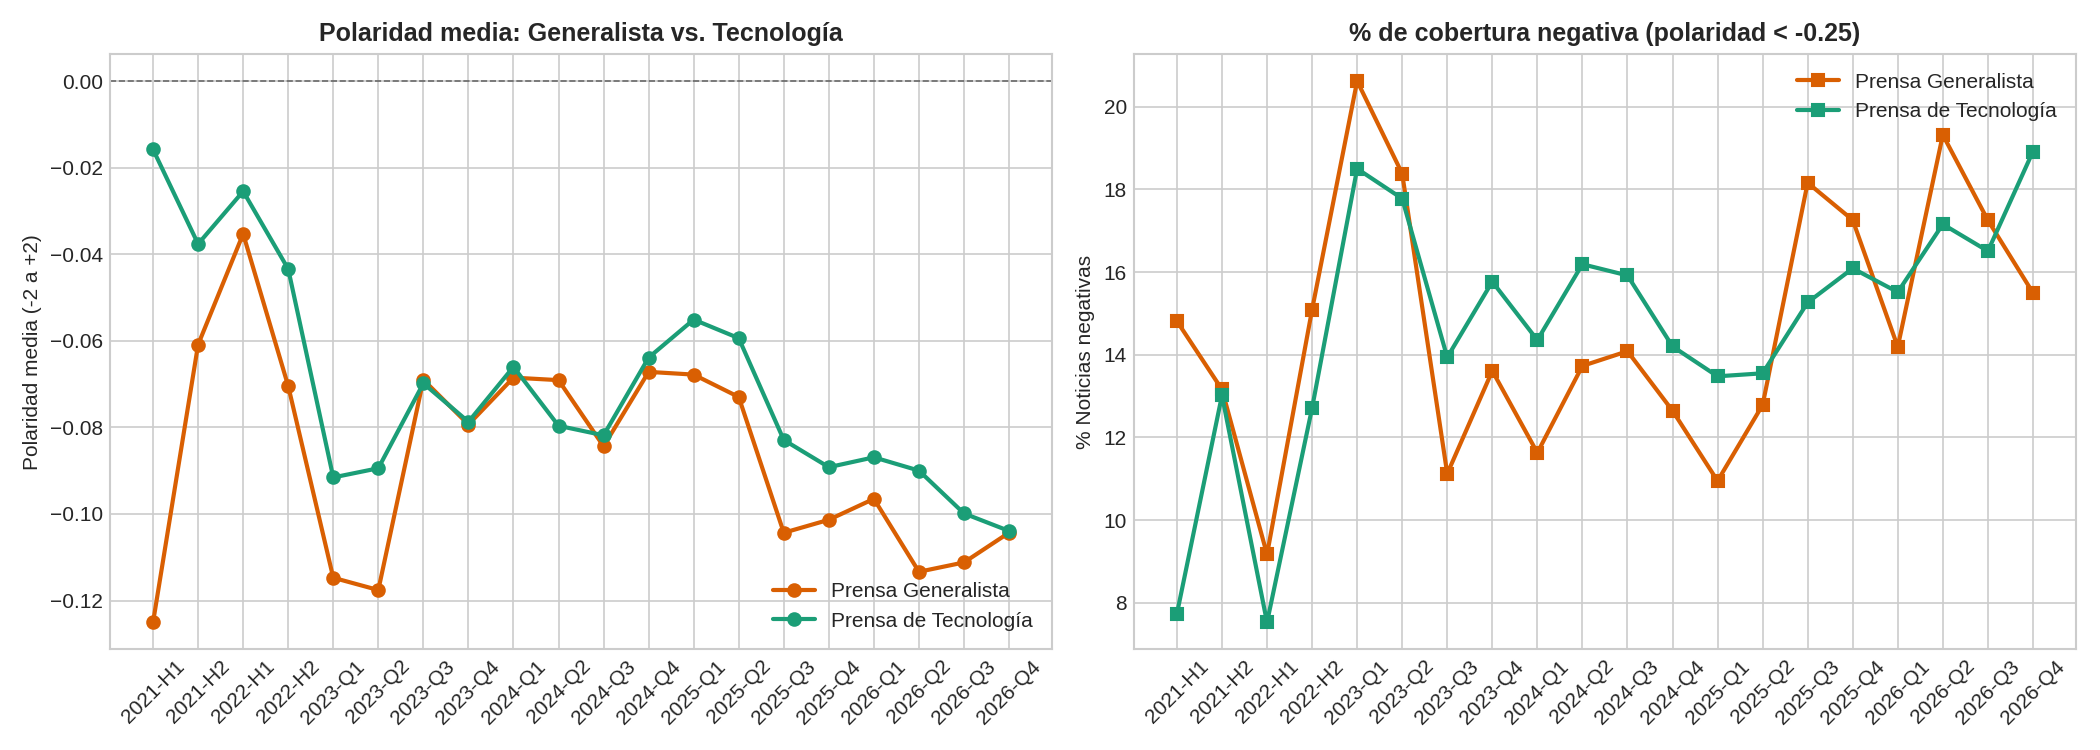

idioma,diario,tipo,total_noticias,polaridad_media,pct_negativo,pct_positivo
de,spiegel.de,generalista,800,-0.103,14.0%,0.6%
de,sueddeutsche.de,generalista,642,-0.102,14.8%,0.6%
de,welt.de,generalista,451,-0.079,12.2%,0.4%
de,focus.de,generalista,"1,000",-0.078,11.3%,1.0%
de,t3n.de,tecnologia,"1,364",-0.062,11.1%,2.3%
de,dw.com,generalista,215,-0.060,9.3%,0.0%
de,heise.de,tecnologia,"4,740",-0.045,6.5%,0.6%
de,n-tv.de,generalista,280,-0.042,6.1%,0.7%
de,faz.net,generalista,101,-0.037,5.9%,0.0%
en,theguardian.com,generalista,"2,925",-0.231,38.8%,2.3%


idioma,de,en,es,fr,pt
periodo,,,,,
2021-H1,-0.223,-0.044,-0.019,-0.058,-0.087
2021-H2,-0.082,-0.103,+0.005,-0.044,-0.031
2022-H1,-0.043,-0.061,+0.004,-0.034,-0.009
2022-H2,-0.054,-0.092,-0.093,-0.068,-0.020
2023-Q1,-0.108,-0.084,-0.106,-0.187,-0.042
2023-Q2,-0.086,-0.126,-0.135,-0.138,-0.065
2023-Q3,-0.055,-0.088,-0.060,-0.115,-0.033
2023-Q4,-0.058,-0.092,-0.048,-0.146,-0.054
2024-Q1,-0.057,-0.105,-0.043,-0.104,-0.034


idioma,tipo,periodos_activos,noticias_totales,polaridad_promedio,pct_negativo_promedio
de,generalista,20,"3,489",-0.082,12.0%
de,tecnologia,20,"6,104",-0.048,7.3%
en,generalista,20,"3,943",-0.183,32.5%
en,tecnologia,20,"16,193",-0.071,18.3%
es,generalista,20,"10,056",-0.058,12.8%
es,tecnologia,17,"2,997",-0.111,21.5%
fr,generalista,20,"5,206",-0.120,17.7%
fr,tecnologia,20,"6,863",-0.106,18.0%
pt,generalista,20,"16,916",-0.059,10.5%
pt,tecnologia,20,"6,604",-0.017,4.5%



📦 Paquete listo: 'entregables_analisis_ia_2021_2026.zip'


In [4]:
import os
import zipfile
import pandas as pd
from IPython.display import display, HTML, Image

# Archivos esperados de la Fase 3
ENTREGABLES = {
    "serie_idiomas": "resultado_serie_temporal_idiomas.csv",
    "serie_tipo": "resultado_serie_generalista_vs_tech.csv",
    "ranking_diarios": "resultado_ranking_diarios.csv",
    "grafica_idiomas": "grafica_1_evolucion_idiomas.png",
    "grafica_tipo": "grafica_2_generalista_vs_tecnologia.png",
}

faltantes = [f for f in ENTREGABLES.values() if not os.path.exists(f)]
if faltantes:
    print("⚠️ Faltan los siguientes archivos en el directorio actual de Colab:")
    for f in faltantes:
        print(f"   - {f}")
    print("\nSúbelos al panel izquierdo de Colab o monta tu Google Drive con:")
    print("from google.colab import drive; drive.mount('/content/drive')")
else:
    df_idiomas = pd.read_csv(ENTREGABLES["serie_idiomas"])
    df_tipo = pd.read_csv(ENTREGABLES["serie_tipo"])
    df_diarios = pd.read_csv(ENTREGABLES["ranking_diarios"])

    def titulo_seccion(texto: str):
        display(HTML(
            f"<h2 style='border-bottom: 2px solid #2b5c8f; padding-bottom: 6px; "
            f"margin-top: 28px; color: #1f3b5c;'>{texto}</h2>"
        ))

    # =========================================================================
    # 1. HALLAZGOS RÁPIDOS AUTOMÁTICOS
    # =========================================================================
    titulo_seccion("1. Resumen Ejecutivo de Hallazgos (2021–2026)")

    idx_min = df_idiomas["polaridad_ponderada_diario"].idxmin()
    idx_max = df_idiomas["polaridad_ponderada_diario"].idxmax()
    p_min = df_idiomas.loc[idx_min]
    p_max = df_idiomas.loc[idx_max]

    diario_critico = df_diarios.iloc[0]
    diario_optimista = df_diarios.iloc[-1]

    resumen_html = f"""
    <div style="background-color: #f4f7fa; border-left: 4px solid #2b5c8f; padding: 14px 18px; border-radius: 4px; font-size: 14px; line-height: 1.6;">
        <b>• Periodo más crítico:</b> <code>{p_min['idioma'].upper()}</code> en <b>{p_min['periodo']}</b>
        (polaridad: <b>{p_min['polaridad_ponderada_diario']:+.3f}</b> | {p_min['pct_negativo']:.1f}% negativo).<br>
        <b>• Periodo más favorable:</b> <code>{p_max['idioma'].upper()}</code> en <b>{p_max['periodo']}</b>
        (polaridad: <b>{p_max['polaridad_ponderada_diario']:+.3f}</b> | {p_max['pct_positivo']:.1f}% positivo).<br>
        <b>• Diario con tono más crítico:</b> <b>{diario_critico['diario']}</b> ({diario_critico['idioma'].upper()}, {diario_critico['tipo']})
        con polaridad <b>{diario_critico['polaridad_media']:+.3f}</b> ({diario_critico['pct_negativo']:.1f}% negativo en {diario_critico['total_noticias']:,} noticias).<br>
        <b>• Diario con tono más favorable:</b> <b>{diario_optimista['diario']}</b> ({diario_optimista['idioma'].upper()}, {diario_optimista['tipo']})
        con polaridad <b>{diario_optimista['polaridad_media']:+.3f}</b> ({diario_optimista['pct_positivo']:.1f}% positivo en {diario_optimista['total_noticias']:,} noticias).
    </div>
    """
    display(HTML(resumen_html))

    # =========================================================================
    # 2. GRÁFICAS DE EVOLUCIÓN TEMPORAL
    # =========================================================================
    titulo_seccion("2. Visualizaciones de Evolución Temporal")
    display(HTML("<h4>Gráfica 1: Evolución del tono mediático por idioma (ponderado por diario)</h4>"))
    display(Image(filename=ENTREGABLES["grafica_idiomas"], width=900))

    display(HTML("<h4>Gráfica 2: Comparativa Prensa Generalista vs. Tecnología</h4>"))
    display(Image(filename=ENTREGABLES["grafica_tipo"], width=950))

    # =========================================================================
    # 3. RANKING EDITORIAL DE LOS 37 DIARIOS
    # =========================================================================
    titulo_seccion("3. Ranking Editorial por Diario (Ordenado de más crítico a más favorable)")
    tabla_diarios = (
        df_diarios.style
        .format({
            "total_noticias": "{:,}",
            "polaridad_media": "{:+.3f}",
            "pct_negativo": "{:.1f}%",
            "pct_positivo": "{:.1f}%",
        })
        .background_gradient(subset=["polaridad_media"], cmap="RdYlGn", vmin=-0.35, vmax=0.15)
        .hide(axis="index")
    )
    display(tabla_diarios)

    # =========================================================================
    # 4. TABLA PIVOTE: POLARIDAD POR IDIOMA Y PERIODO
    # =========================================================================
    titulo_seccion("4. Matriz Temporal de Polaridad por Idioma")
    pivote_idiomas = df_idiomas.pivot(
        index="periodo",
        columns="idioma",
        values="polaridad_ponderada_diario"
    )
    tabla_pivote = (
        pivote_idiomas.style
        .format("{:+.3f}", na_rep="—")
        .background_gradient(cmap="RdYlGn", vmin=-0.30, vmax=0.15)
    )
    display(tabla_pivote)

    # =========================================================================
    # 5. RESUMEN COMPARATIVO GENERALISTA VS. TECNOLOGÍA POR IDIOMA
    # =========================================================================
    titulo_seccion("5. Resumen Agregado: Generalista vs. Tecnología por Idioma")
    resumen_tipo = (
        df_tipo.groupby(["idioma", "tipo"], as_index=False)
        .agg(
            periodos_activos=("periodo", "count"),
            noticias_totales=("n_noticias", "sum"),
            polaridad_promedio=("polaridad_media", "mean"),
            pct_negativo_promedio=("pct_negativo", "mean"),
        )
    )
    tabla_tipo = (
        resumen_tipo.style
        .format({
            "noticias_totales": "{:,}",
            "polaridad_promedio": "{:+.3f}",
            "pct_negativo_promedio": "{:.1f}%",
        })
        .background_gradient(subset=["polaridad_promedio"], cmap="RdYlGn", vmin=-0.30, vmax=0.10)
        .hide(axis="index")
    )
    display(tabla_tipo)

    # =========================================================================
    # 6. EMPAQUETAR TODO EN UN .ZIP PARA DESCARGA DIRECTA
    # =========================================================================
    nombre_zip = "entregables_analisis_ia_2021_2026.zip"
    with zipfile.ZipFile(nombre_zip, "w", zipfile.ZIP_DEFLATED) as zf:
        for ruta in ENTREGABLES.values():
            zf.write(ruta)
        # Incluir también los parquet principales si están en la carpeta
        for extra in ["sentimiento_por_noticia.parquet", "sentimiento_por_fragmento.parquet"]:
            if os.path.exists(extra):
                zf.write(extra)

    print(f"\n📦 Paquete listo: '{nombre_zip}'")
    # Descomenta las dos líneas siguientes si quieres que Colab inicie la descarga automáticamente:
    # from google.colab import files
    # files.download(nombre_zip)

In [6]:
import gc
import hashlib
import json
import os
import platform
import re
import shutil
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import torch
from tqdm.auto import tqdm
from transformers import AutoModelForSequenceClassification, AutoTokenizer
from huggingface_hub import hf_hub_download

# ==============================================================================
# 1. CONFIGURACIÓN PARA GOOGLE COLAB (Modifica aquí según necesites)
# ==============================================================================
CONFIG = {
    # Busca automáticamente en /content/ o en Google Drive
    "archivo_entrada": "noticias_preparadas.parquet",
    "dir_resultados": Path("/content/resultados_emociones"),
    "dir_modelos": Path("/content/modelos_cache"),
    "modelo_id": "Horizon-Labs/multilingual-emotions-base",

    # Parámetros de ejecución
    "muestra_por_idioma": None,    # Pon ej. 100 para prueba rápida; None = TODO el corpus
    "idiomas": None,               # Ej. ["es", "en"] o None = todos
    "batch_size": 64,              # 64 es óptimo en GPU T4 de Colab con FP16
    "max_tokens": 256,             # Límite nativo del modelo (256 tokens)
    "max_fragmentos": 0,           # 0 = procesa toda la noticia; >0 = muestreo uniforme
    "umbral_global": None,         # None = usa thresholds.json oficial por emoción
    "min_prevalencia": 0.5,        # % mínimo de tokens sobre umbral para detectar emoción
    "tamano_bloque": 512,          # Noticias por bloque de guardado (checkpoints)
    "guardar_texto_frags": False,  # False ahorra mucho espacio en disco
    "exportar_csv": True,          # Genera también emociones_por_noticia.csv
    "forzar_reinicio": False,      # True borra caché previa y recalcula desde cero
    "semilla": 42,
}

ALGORITMO = "v1-parrafos-oraciones-colab"
RE_ORACION = re.compile(r"(?<=[.!?…»”\"])\s+")

# ==============================================================================
# 2. LOCALIZAR ARCHIVO DE ENTRADA EN COLAB / DRIVE
# ==============================================================================
def localizar_archivo(nombre: str) -> Path:
    rutas_posibles = [
        Path(nombre),
        Path("/content") / nombre,
        Path("/content/datos/preparados") / nombre,
        Path("/content/drive/MyDrive") / nombre,
    ]
    for r in rutas_posibles:
        if r.exists():
            return r.resolve()
    raise FileNotFoundError(
        f"❌ No se encontró '{nombre}' en /content/ ni en Google Drive.\n"
        "Súbelo en el panel izquierdo de archivos o monta Drive con:\n"
        "from google.colab import drive; drive.mount('/content/drive')"
    )

ARCHIVO_PREPARADO = localizar_archivo(CONFIG["archivo_entrada"])

# Detectar automáticamente la columna de texto disponible
schema_cols = pq.ParquetFile(ARCHIVO_PREPARADO).schema_arrow.names
COL_TEXTO = next((c for c in ["texto_limpio", "texto", "texto_modelo", "text"] if c in schema_cols), None)
if not COL_TEXTO or "id" not in schema_cols:
    raise ValueError(f"El archivo debe tener 'id' y una columna de texto. Columnas actuales: {schema_cols}")

print(f"✅ Archivo localizado: {ARCHIVO_PREPARADO}")
print(f"✅ Columna de texto detectada: '{COL_TEXTO}'")

# ==============================================================================
# 3. FUNCIONES AUXILIARES, TOKENIZACIÓN Y FRAGMENTACIÓN
# ==============================================================================
def hash_texto(t: str) -> str:
    return hashlib.blake2b(t.encode("utf-8"), digest_size=16).hexdigest()

def escritura_atomica_parquet(tabla: pa.Table, destino: Path):
    tmp = destino.with_suffix(destino.suffix + ".tmp")
    pq.write_table(tabla, tmp, compression="zstd")
    os.replace(tmp, destino)

def tokens_especiales(tok) -> tuple[list[int], list[int]]:
    con = tok("a", add_special_tokens=True)["input_ids"]
    sin = tok("a", add_special_tokens=False)["input_ids"]
    for i in range(len(con) - len(sin) + 1):
        if con[i:i + len(sin)] == sin:
            return con[:i], con[i + len(sin):]
    raise RuntimeError("No se pudieron determinar los tokens especiales del tokenizer.")

def tokenizar(tok, textos: list[str]) -> list[list[int]]:
    if not textos:
        return []
    return tok(textos, add_special_tokens=False, return_attention_mask=False)["input_ids"]

def dividir_parrafo_largo(texto: str, presupuesto: int, tok, guardar_texto: bool):
    oraciones = [s for s in RE_ORACION.split(texto) if s.strip()]
    ids_or = tokenizar(tok, oraciones)
    piezas, cur_ids, cur_t = [], [], []

    def volcar():
        nonlocal cur_ids, cur_t
        if cur_ids:
            piezas.append((" ".join(cur_t), cur_ids))
        cur_ids, cur_t = [], []

    for s, ids in zip(oraciones, ids_or):
        if not ids:
            continue
        if len(ids) > presupuesto:
            volcar()
            for k in range(0, len(ids), presupuesto):
                w = ids[k:k + presupuesto]
                piezas.append((tok.decode(w) if guardar_texto else "", w))
            continue
        if cur_ids and len(cur_ids) + len(ids) > presupuesto:
            volcar()
        cur_ids = cur_ids + ids
        cur_t.append(s)
    volcar()
    return piezas

def fragmentar(parrafos: list[str], ids_parr: list[list[int]], presupuesto: int, tok, guardar_texto: bool):
    piezas = []
    for t, ids in zip(parrafos, ids_parr):
        if not ids:
            continue
        if len(ids) <= presupuesto:
            piezas.append((t, ids))
        else:
            piezas.extend(dividir_parrafo_largo(t, presupuesto, tok, guardar_texto))
    frags, cur_ids, cur_t = [], [], []
    for t, ids in piezas:
        if cur_ids and len(cur_ids) + len(ids) > presupuesto:
            frags.append((cur_ids, "\n".join(cur_t) if guardar_texto else None))
            cur_ids, cur_t = [], []
        cur_ids = cur_ids + ids
        cur_t.append(t)
    if cur_ids:
        frags.append((cur_ids, "\n".join(cur_t) if guardar_texto else None))
    return frags

def fragmentar_bloque(textos: list[str], presupuesto: int, tok, max_fragmentos: int, guardar_texto: bool):
    por_noticia_parrafos = [[p for p in t.split("\n") if p.strip()] for t in textos]
    planos = [p for ps in por_noticia_parrafos for p in ps]
    ids_planos = tokenizar(tok, planos)
    salida, pos = [], 0
    for ps in por_noticia_parrafos:
        ids_ps = ids_planos[pos:pos + len(ps)]
        pos += len(ps)
        frs = fragmentar(ps, ids_ps, presupuesto, tok, guardar_texto)
        total = len(frs)
        indices = list(range(total))
        if max_fragmentos and total > max_fragmentos:
            indices = sorted(set(np.linspace(0, total - 1, max_fragmentos).round().astype(int).tolist()))
        salida.append((total, [(i, frs[i][0], frs[i][1]) for i in indices]))
    return salida

def predecir(modelo, dispositivo: str, lista_ids: list[list[int]], pre: list[int], suf: list[int],
             pad_id: int, lote: int, n_etq: int):
    n = len(lista_ids)
    out = np.full((n, n_etq), np.nan, dtype=np.float32)
    errores: dict[int, str] = {}
    orden = sorted(range(n), key=lambda i: -len(lista_ids[i]))
    i, tam = 0, max(1, lote)
    while i < n:
        idx = orden[i:i + tam]
        try:
            secuencias = [pre + lista_ids[j] + suf for j in idx]
            L = max(len(s) for s in secuencias)
            ids_t = torch.full((len(idx), L), pad_id, dtype=torch.long)
            mask = torch.zeros((len(idx), L), dtype=torch.long)
            for r, s in enumerate(secuencias):
                ids_t[r, :len(s)] = torch.tensor(s, dtype=torch.long)
                mask[r, :len(s)] = 1
            with torch.inference_mode():
                logits = modelo(input_ids=ids_t.to(dispositivo), attention_mask=mask.to(dispositivo)).logits
            out[idx] = torch.sigmoid(logits.float()).cpu().numpy()
            i += len(idx)
        except Exception as e:
            if dispositivo == "cuda":
                torch.cuda.empty_cache()
            if tam > 1:
                tam = max(1, tam // 2)
                print(f"\n⚠️ Ajuste automático de lote por memoria -> nuevo batch_size={tam}")
                continue
            errores[idx[0]] = f"{type(e).__name__}: {e}"
            i += 1
    return out, errores

def agregar(frag: pd.DataFrame, etiquetas, thr, ekman, min_prev):
    L = len(etiquetas)
    P = frag[[f"p_{e}" for e in etiquetas]].to_numpy(np.float64)
    w = frag["n_tokens"].to_numpy(np.float64)
    codigos, ids = pd.factorize(frag["id"])
    G = len(ids)
    sw = np.bincount(codigos, weights=w, minlength=G)
    sw_seguro = np.where(sw > 0, sw, np.nan)
    media = np.empty((G, L))
    prev = np.empty((G, L))
    for j in range(L):
        media[:, j] = np.bincount(codigos, weights=w * P[:, j], minlength=G) / sw_seguro
        prev[:, j] = np.bincount(codigos, weights=w * (P[:, j] >= thr[j]), minlength=G) / sw_seguro
    mx = pd.DataFrame(P).groupby(codigos).max().to_numpy()
    det = prev >= min_prev
    alguno = mx >= thr[None, :]

    grupos = list(ekman.keys())
    E = np.column_stack([P[:, [etiquetas.index(l) for l in ekman[g]]].max(axis=1) for g in grupos])
    e_media = np.empty((G, len(grupos)))
    for j in range(len(grupos)):
        e_media[:, j] = np.bincount(codigos, weights=w * E[:, j], minlength=G) / sw_seguro
    e_max = pd.DataFrame(E).groupby(codigos).max().to_numpy()
    e_det = np.column_stack([det[:, [etiquetas.index(l) for l in ekman[g]]].any(axis=1) for g in grupos])

    et = np.array(etiquetas)
    df = pd.DataFrame({"id": ids})
    df["n_fragmentos_procesados"] = np.bincount(codigos, minlength=G).astype(np.int32)
    df["n_tokens_total"] = sw.astype(np.int64)
    df["emociones_detectadas"] = [";".join(et[r]) for r in det]
    df["n_emociones_detectadas"] = det.sum(axis=1).astype(np.int16)
    df["emociones_en_algun_fragmento"] = [";".join(et[r]) for r in alguno]
    df["ekman_detectadas"] = [";".join(np.array(grupos)[r]) for r in e_det]
    cols = {}
    for j, e in enumerate(etiquetas):
        cols[f"det_{e}"] = det[:, j]
        cols[f"media_{e}"] = media[:, j].astype(np.float32)
        cols[f"max_{e}"] = mx[:, j].astype(np.float32)
        cols[f"prev_{e}"] = prev[:, j].astype(np.float32)
    for j, g in enumerate(grupos):
        cols[f"ekman_media_{g}"] = e_media[:, j].astype(np.float32)
        cols[f"ekman_max_{g}"] = e_max[:, j].astype(np.float32)
    return pd.concat([df, pd.DataFrame(cols)], axis=1)

# ==============================================================================
# 4. PIPELINE PRINCIPAL EN COLAB
# ==============================================================================
def ejecutar_colab():
    t0 = time.time()
    salida_dir = CONFIG["dir_resultados"] / ("prueba" if CONFIG["muestra_por_idioma"] else "")
    salida_dir.mkdir(parents=True, exist_ok=True)
    CONFIG["dir_modelos"].mkdir(parents=True, exist_ok=True)

    # Leer metadatos ligeros sin cargar textos pesados en RAM
    cols_meta = [c for c in schema_cols if c not in ("texto_original", "texto_limpio", "texto", "texto_modelo")]
    meta = pq.read_table(ARCHIVO_PREPARADO, columns=cols_meta).to_pandas()
    meta["id"] = meta["id"].astype(str)
    total_corpus = len(meta)

    if CONFIG["idiomas"] and "idioma" in meta.columns:
        meta = meta[meta["idioma"].isin(CONFIG["idiomas"])]
    if CONFIG["muestra_por_idioma"] and "idioma" in meta.columns:
        meta = pd.concat([
            g.sample(min(CONFIG["muestra_por_idioma"], len(g)), random_state=CONFIG["semilla"])
            for _, g in meta.groupby("idioma")
        ])
        print(f"*** MODO MUESTRA: {CONFIG['muestra_por_idioma']} noticias por idioma ({len(meta):,} total) ***")
    meta = meta.reset_index(drop=True)
    ids_objetivo = set(meta["id"])
    print(f"Noticias a procesar: {len(meta):,} de {total_corpus:,}")

    # Cargar Tokenizer y Modelo en FP16 si hay GPU
    dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
    dtype = torch.float16 if dispositivo == "cuda" else torch.float32
    print(f"Cargando '{CONFIG['modelo_id']}' en {dispositivo.upper()} ({dtype})...")

    tok = AutoTokenizer.from_pretrained(CONFIG["modelo_id"], cache_dir=str(CONFIG["dir_modelos"]))
    tok.model_max_length = int(1e9)
    modelo = AutoModelForSequenceClassification.from_pretrained(
        CONFIG["modelo_id"], torch_dtype=dtype, cache_dir=str(CONFIG["dir_modelos"])
    ).to(dispositivo).eval()

    # Leer umbrales oficiales (thresholds.json) y mapeo Ekman (ekman_mapping.json)
    cfg = modelo.config
    etiquetas = [cfg.id2label[i] for i in range(len(cfg.id2label))]
    n_etq = len(etiquetas)

    p_thr = Path(hf_hub_download(CONFIG["modelo_id"], "thresholds.json", cache_dir=str(CONFIG["dir_modelos"])))
    p_ekm = Path(hf_hub_download(CONFIG["modelo_id"], "ekman_mapping.json", cache_dir=str(CONFIG["dir_modelos"])))
    thr_oficial = json.loads(p_thr.read_text(encoding="utf-8"))
    ekman = json.loads(p_ekm.read_text(encoding="utf-8"))

    if CONFIG["umbral_global"] is not None:
        thr = np.full(n_etq, float(CONFIG["umbral_global"]), dtype=np.float64)
        modo_umbral = f"global={CONFIG['umbral_global']}"
    else:
        thr = np.array([float(thr_oficial.get(e, 0.5)) for e in etiquetas], dtype=np.float64)
        modo_umbral = "por_emocion(thresholds.json)"

    pre, suf = tokens_especiales(tok)
    presupuesto = CONFIG["max_tokens"] - len(pre) - len(suf)
    pad_id = tok.pad_token_id if tok.pad_token_id is not None else 0

    # Gestión de caché por bloques
    huella = hash_texto(json.dumps({
        "modelo": CONFIG["modelo_id"], "max_tokens": CONFIG["max_tokens"],
        "max_fragmentos": CONFIG["max_fragmentos"], "algoritmo": ALGORITMO,
    }, sort_keys=True))[:16]
    cache_dir = CONFIG["dir_resultados"] / "cache_fragmentos" / huella
    if CONFIG["forzar_reinicio"] and cache_dir.exists():
        shutil.rmtree(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)

    hechos = set()
    for p in cache_dir.glob("parte_*.parquet"):
        t = pq.read_table(p, columns=["id", "hash_texto"]).to_pandas()
        hechos.update(zip(t["id"], t["hash_texto"]))

    # Mapear hashes y filtrar pendientes
    hash_de = {}
    pf = pq.ParquetFile(ARCHIVO_PREPARADO)
    for b in pf.iter_batches(batch_size=4000, columns=["id", COL_TEXTO]):
        d = b.to_pydict()
        for i, t in zip(d["id"], d[COL_TEXTO]):
            i_str = str(i)
            if i_str in ids_objetivo:
                hash_de[i_str] = hash_texto(t or "")

    pendientes = [i for i in meta["id"] if (i, hash_de.get(i)) not in hechos]
    print(f"Reutilizadas de caché: {len(meta) - len(pendientes):,} | Pendientes: {len(pendientes):,}")

    errores_run = {}
    n_frag_calc = 0
    seg_modelo = 0.0

    def procesar_bloque(bloque):
        nonlocal n_frag_calc, seg_modelo
        frs = fragmentar_bloque([t or "" for _, t in bloque], presupuesto, tok,
                                CONFIG["max_fragmentos"], CONFIG["guardar_texto_frags"])
        plano = [(k, f) for k, (_, (_, fl)) in enumerate(zip(bloque, frs)) for f in fl]
        lista_ids = [f[1] for _, f in plano]
        if lista_ids:
            t1 = time.perf_counter()
            probs, errs = predecir(modelo, dispositivo, lista_ids, pre, suf, pad_id, CONFIG["batch_size"], n_etq)
            seg_modelo += time.perf_counter() - t1
            n_frag_calc += len(lista_ids)
        else:
            probs, errs = np.zeros((0, n_etq), np.float32), {}

        malas = {plano[j][0] for j in errs}
        for j, msg in errs.items():
            errores_run[bloque[plano[j][0]][0]] = msg

        filas = []
        for (k, (idx_orig, ids_f, txt)), pr in zip(plano, probs):
            if k in malas:
                continue
            i, _ = bloque[k]
            fila = {
                "id": i, "hash_texto": hash_de[i], "frag_idx": idx_orig,
                "n_tokens": len(ids_f) + len(pre) + len(suf), "n_frag_total": frs[k][0]
            }
            fila.update({f"p_{e}": v for e, v in zip(etiquetas, pr)})
            if CONFIG["guardar_texto_frags"]:
                fila["texto_fragmento"] = txt
            filas.append(fila)

        for k, (i, _) in enumerate(bloque):
            if not frs[k][1] and i not in errores_run:
                fila = {"id": i, "hash_texto": hash_de[i], "frag_idx": 0, "n_tokens": 0, "n_frag_total": 0}
                fila.update({f"p_{e}": np.float32("nan") for e in etiquetas})
                if CONFIG["guardar_texto_frags"]:
                    fila["texto_fragmento"] = ""
                filas.append(fila)

        if filas:
            df_b = pd.DataFrame(filas)
            for c in ("frag_idx", "n_tokens", "n_frag_total"):
                df_b[c] = df_b[c].astype("int32")
            for e in etiquetas:
                df_b[f"p_{e}"] = df_b[f"p_{e}"].astype("float32")
            escritura_atomica_parquet(pa.Table.from_pandas(df_b, preserve_index=False),
                                      cache_dir / f"parte_{time.time_ns()}.parquet")

    if pendientes:
        pend_set = set(pendientes)
        barra = tqdm(total=len(pendientes), desc="Analizando emociones", unit="not.")
        buf = []
        for b in pf.iter_batches(batch_size=2000, columns=["id", COL_TEXTO]):
            d = b.to_pydict()
            for i, t in zip(d["id"], d[COL_TEXTO]):
                i_str = str(i)
                if i_str in pend_set:
                    buf.append((i_str, t))
            while len(buf) >= CONFIG["tamano_bloque"]:
                bl, buf = buf[:CONFIG["tamano_bloque"]], buf[CONFIG["tamano_bloque"]:]
                procesar_bloque(bl)
                barra.update(len(bl))
                barra.set_postfix(frag_s=f"{n_frag_calc / max(seg_modelo, 1e-9):.1f}")
        if buf:
            procesar_bloque(buf)
            barra.update(len(buf))
        barra.close()

    # Liberar VRAM antes de consolidar
    del modelo
    gc.collect()
    if dispositivo == "cuda":
        torch.cuda.empty_cache()

    # Consolidación final
    print("Consolidando resultados...")
    partes = [pq.read_table(p) for p in sorted(cache_dir.glob("parte_*.parquet"))]
    frag = pa.concat_tables(partes, promote_options="default").to_pandas()
    frag = frag[frag["id"].map(hash_de).eq(frag["hash_texto"])]
    frag = frag.drop_duplicates(["id", "hash_texto", "frag_idx"], keep="last")

    frag_ok = frag[frag["n_tokens"] > 0]
    agg = agregar(frag_ok, etiquetas, thr, ekman, CONFIG["min_prevalencia"])
    tot_frag = frag.groupby("id")["n_frag_total"].max().rename("n_fragmentos").reset_index()

    noticias = meta.merge(tot_frag, on="id", how="left").merge(agg, on="id", how="left")
    estado = np.where(noticias["n_fragmentos_procesados"].notna(), "ok",
                      np.where(noticias["n_fragmentos"].eq(0), "sin_texto", "sin_resultado"))
    noticias.insert(len(meta.columns), "estado", estado)

    escritura_atomica_parquet(pa.Table.from_pandas(noticias, preserve_index=False),
                              salida_dir / "emociones_por_noticia.parquet")
    if CONFIG["exportar_csv"]:
        noticias.to_csv(salida_dir / "emociones_por_noticia.csv", index=False, encoding="utf-8-sig")

    ok = noticias[noticias["estado"] == "ok"]
    if len(ok) and "idioma" in ok.columns:
        resumen = [
            {"idioma": idioma, "emocion": e,
             "pct_noticias_detectada": round(100 * g[f"det_{e}"].mean(), 2),
             "media_prob": round(float(g[f"media_{e}"].mean()), 4)}
            for idioma, g in ok.groupby("idioma") for e in etiquetas
        ]
        pd.DataFrame(resumen).to_csv(salida_dir / "resumen_por_idioma.csv", index=False, encoding="utf-8-sig")

    vel = n_frag_calc / seg_modelo if seg_modelo > 0 else 0
    print(f"\n✅ Completado en {(time.time() - t0)/60:.2f} min ({vel:.1f} frag/s)")
    print(f"📁 Archivos guardados en: {salida_dir}")
    if len(ok):
        top = pd.Series({e: ok[f"det_{e}"].mean() for e in etiquetas}).sort_values(ascending=False).head(8)
        print("\nTop 8 emociones detectadas (% de noticias):")
        for k, v in top.items():
            print(f"  • {k:<15}: {100 * v:.1f}%")

ejecutar_colab()

✅ Archivo localizado: /content/noticias_preparadas.parquet
✅ Columna de texto detectada: 'texto_limpio'
Noticias a procesar: 78,360 de 78,360
Cargando 'Horizon-Labs/multilingual-emotions-base' en CUDA (torch.float16)...


config.json:   0%|          | 0.00/3.16k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/46.4k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 34.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

... (4 outputs left out)

ekman_mapping.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

Reutilizadas de caché: 0 | Pendientes: 78,360


Analizando emociones:   0%|          | 0/78360 [00:00<?, ?not./s]

Consolidando resultados...

✅ Completado en 44.00 min (165.0 frag/s)
📁 Archivos guardados en: /content/resultados_emociones

Top 8 emociones detectadas (% de noticias):
  • neutral        : 98.8%
  • realization    : 3.3%
  • approval       : 1.9%
  • optimism       : 1.7%
  • admiration     : 0.8%
  • curiosity      : 0.2%
  • caring         : 0.1%
  • disapproval    : 0.1%
